In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/usdot/flight-delays/airlines.csv
/kaggle/input/datasets/usdot/flight-delays/airports.csv
/kaggle/input/datasets/usdot/flight-delays/flights.csv


In [2]:
path = '/kaggle/input/datasets/usdot/flight-delays/'
cols = ['MONTH','DAY_OF_WEEK','AIRLINE','ORIGIN_AIRPORT','SCHEDULED_DEPARTURE',
        'DISTANCE','ARRIVAL_DELAY','CANCELLED','DIVERTED',
        'AIR_SYSTEM_DELAY','SECURITY_DELAY','AIRLINE_DELAY','LATE_AIRCRAFT_DELAY','WEATHER_DELAY']
df = pd.read_csv(path + 'flights.csv', usecols=cols, low_memory=False)
print(df.shape)

df = df[(df.CANCELLED == 0) & (df.DIVERTED == 0)].dropna(subset=['ARRIVAL_DELAY'])
df = df.sample(500_000, random_state=42).reset_index(drop=True)

airlines = pd.read_csv(path + 'airlines.csv')
df = df.merge(airlines, left_on='AIRLINE', right_on='IATA_CODE', how='left', suffixes=('', '_NAME'))

df['delayed'] = (df.ARRIVAL_DELAY > 15).astype(int)
df['dep_hour'] = df.SCHEDULED_DEPARTURE // 100
df['is_weekend'] = df.DAY_OF_WEEK.isin([6, 7]).astype(int)
df['ORIGIN_AIRPORT'] = df.ORIGIN_AIRPORT.astype(str)
print(df.delayed.mean())

(5819079, 14)
0.178992


In [4]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

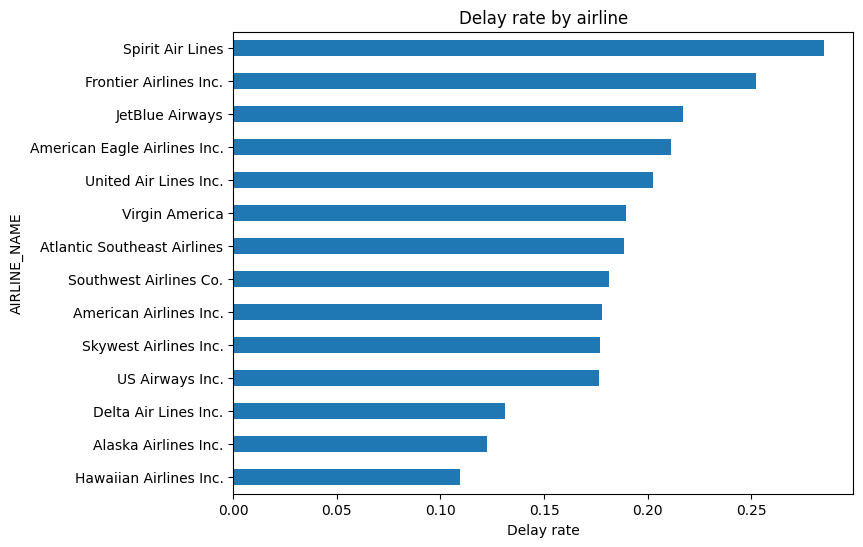

In [5]:
a = df.groupby('AIRLINE_NAME').delayed.mean().sort_values()
a.plot(kind='barh', figsize=(8,6), title='Delay rate by airline')
plt.xlabel('Delay rate'); plt.show()

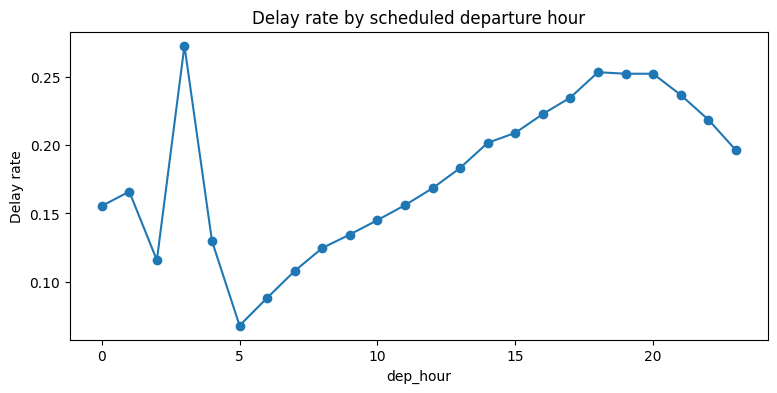

In [6]:
df.groupby('dep_hour').delayed.mean().plot(marker='o', figsize=(9,4), title='Delay rate by scheduled departure hour')
plt.ylabel('Delay rate'); plt.show()

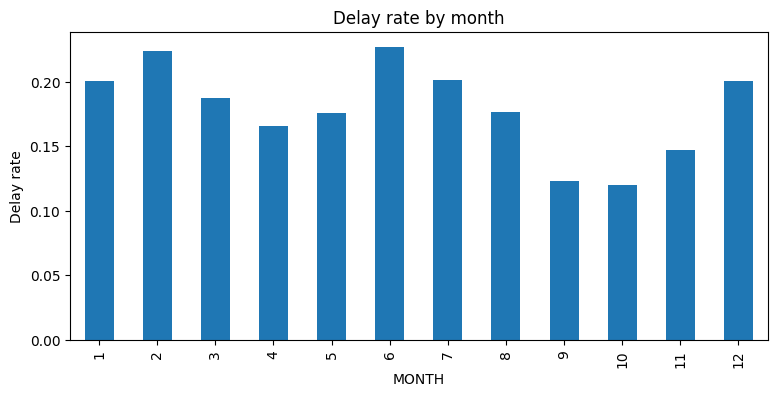

In [7]:
df.groupby('MONTH').delayed.mean().plot(kind='bar', figsize=(9,4), title='Delay rate by month')
plt.ylabel('Delay rate'); plt.show()

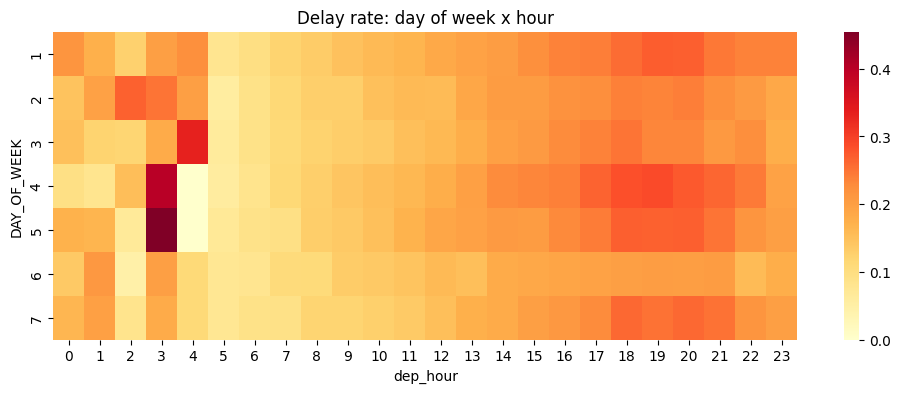

In [8]:
pv = df.pivot_table(index='DAY_OF_WEEK', columns='dep_hour', values='delayed', aggfunc='mean')
plt.figure(figsize=(12,4)); sns.heatmap(pv, cmap='YlOrRd')
plt.title('Delay rate: day of week x hour'); plt.show()

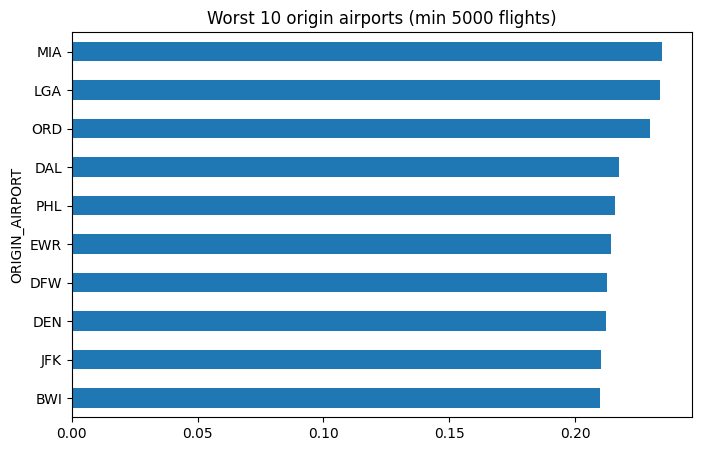

In [9]:
g = df.groupby('ORIGIN_AIRPORT').delayed.agg(['mean','count'])
g[g['count'] > 5000].sort_values('mean', ascending=False).head(10)['mean'].sort_values().plot(
    kind='barh', figsize=(8,5), title='Worst 10 origin airports (min 5000 flights)')
plt.show()

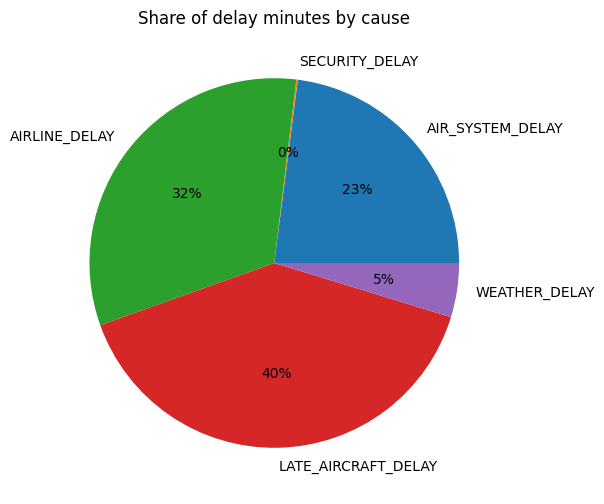

In [10]:
causes = df[['AIR_SYSTEM_DELAY','SECURITY_DELAY','AIRLINE_DELAY','LATE_AIRCRAFT_DELAY','WEATHER_DELAY']].sum()
causes.plot(kind='pie', autopct='%1.0f%%', figsize=(6,6), title='Share of delay minutes by cause')
plt.ylabel(''); plt.show()

In [11]:
from scipy import stats

# 1. Chi-square: is delay related to airline?
ct = pd.crosstab(df.AIRLINE, df.delayed)
chi2, p, dof, _ = stats.chi2_contingency(ct)
print('Chi-square:', round(chi2,1), '| p-value:', p)

# 2. Welch t-test: weekend vs weekday arrival delay
wk = df[df.is_weekend==1].ARRIVAL_DELAY
wd = df[df.is_weekend==0].ARRIVAL_DELAY
print('Weekend mean delay:', round(wk.mean(),2), '| Weekday mean delay:', round(wd.mean(),2))
print(stats.ttest_ind(wk, wd, equal_var=False))

# 3. ANOVA: arrival delay across months
print(stats.f_oneway(*[g.ARRIVAL_DELAY.values for _, g in df.groupby('MONTH')]))

Chi-square: 3398.0 | p-value: 0.0
Weekend mean delay: 2.91 | Weekday mean delay: 4.9
TtestResult(statistic=np.float64(-15.725807533860603), pvalue=np.float64(1.0763877100268458e-55), df=np.float64(229740.9310584541))
F_onewayResult(statistic=np.float64(287.334840889784), pvalue=np.float64(0.0))


## Statistical Testing

**Test 1: Chi-square test (delay vs. airline)**
- H0: Whether a flight is delayed is independent of the airline.
- Result: χ² = 3398, p < 0.001 → reject H0.
- Conclusion: Delay likelihood depends significantly on the airline. The effect is also practically large: delay rates range from about 11% (Hawaiian) to about 28% (Spirit).

**Test 2: Welch's t-test (weekend vs. weekday arrival delay)**
- H0: Mean arrival delay is the same on weekends and weekdays.
- Result: weekend mean = 2.91 min, weekday mean = 4.90 min, t = -15.7, p < 0.001 → reject H0.
- Conclusion: Weekend flights are statistically significantly less delayed, but the practical difference is only about 2 minutes on average. The large sample size makes even small differences significant, so the effect size matters more than the p-value here.

**Test 3: One-way ANOVA (arrival delay across months)**
- H0: Mean arrival delay is equal across all 12 months.
- Result: F = 287.3, p < 0.001 → reject H0.
- Conclusion: Delays vary significantly by month, consistent with the seasonal peaks seen in the EDA (winter and summer high, autumn low).

In [13]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import roc_auc_score, classification_report, confusion_matrix

top = df.ORIGIN_AIRPORT.value_counts().head(30).index
df['origin_grp'] = np.where(df.ORIGIN_AIRPORT.isin(top), df.ORIGIN_AIRPORT, 'OTHER')

feat = ['MONTH','DAY_OF_WEEK','dep_hour','DISTANCE','is_weekend','AIRLINE','origin_grp']
X = pd.get_dummies(df[feat], columns=['AIRLINE','origin_grp']).astype(float)
y = df.delayed

train = df.MONTH <= 9          # train: Jan-Sep, test: Oct-Dec
X_tr, X_te, y_tr, y_te = X[train], X[~train], y[train], y[~train]
sc = StandardScaler().fit(X_tr)
print(X_tr.shape, X_te.shape)

(375968, 50) (124032, 50)


In [14]:
models = {
  'Logistic Regression': (LogisticRegression(max_iter=1000, class_weight='balanced'), True),
  'Random Forest': (RandomForestClassifier(n_estimators=100, max_depth=12, min_samples_leaf=50,
                                           class_weight='balanced', n_jobs=-1, random_state=42), False),
  'XGBoost': (XGBClassifier(n_estimators=300, max_depth=6, learning_rate=0.1, subsample=0.8,
                            scale_pos_weight=(y_tr==0).sum()/(y_tr==1).sum(),
                            tree_method='hist', n_jobs=-1, random_state=42), False),
}
results = {}
for name, (m, scaled) in models.items():
    m.fit(sc.transform(X_tr) if scaled else X_tr, y_tr)
    p_ = m.predict_proba(sc.transform(X_te) if scaled else X_te)[:,1]
    results[name] = roc_auc_score(y_te, p_)
    print(name, 'AUC:', round(results[name], 3))

Logistic Regression AUC: 0.598
Random Forest AUC: 0.61
XGBoost AUC: 0.604


              precision    recall  f1-score   support

           0       0.86      0.87      0.87    104726
           1       0.23      0.21      0.22     19306

    accuracy                           0.77    124032
   macro avg       0.55      0.54      0.54    124032
weighted avg       0.76      0.77      0.76    124032

[[91460 13266]
 [15268  4038]]


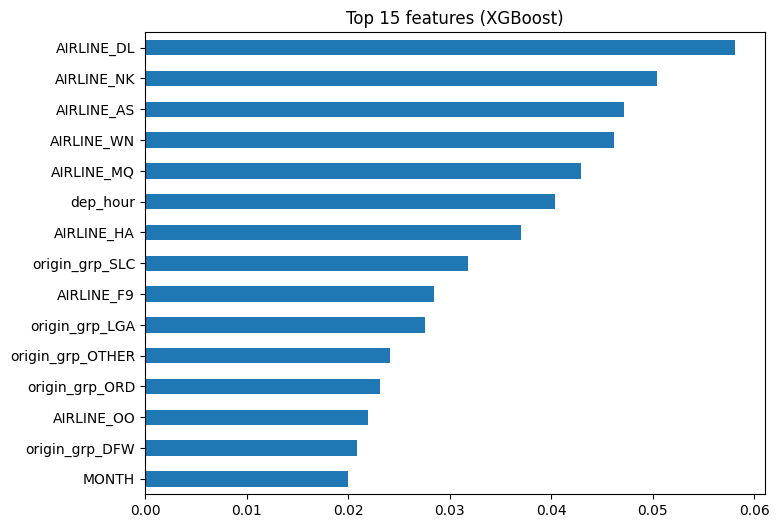

In [15]:
xgb = models['XGBoost'][0]
prob = xgb.predict_proba(X_te)[:,1]
pred = (prob > 0.5).astype(int)
print(classification_report(y_te, pred))
print(confusion_matrix(y_te, pred))

imp = pd.Series(xgb.feature_importances_, index=X.columns).sort_values().tail(15)
imp.plot(kind='barh', figsize=(8,6), title='Top 15 features (XGBoost)'); plt.show()

## Model Results

| Model | ROC-AUC (Oct-Dec test set) |
|---|---|
| Logistic Regression | 0.598 |
| Random Forest | 0.610 |
| XGBoost | 0.604 |

- Models were trained on Jan-Sep and tested on Oct-Dec (time-based split) to avoid leakage. Only pre-departure information was used.
- At the default threshold, XGBoost flags delayed flights with precision 0.23 and recall 0.21, against a base delay rate of ~15.6%, a lift of about 1.5x. Accuracy (77%) is not a useful metric here because the classes are imbalanced.
- Top drivers: airline, scheduled departure hour, and origin airport (e.g. LGA, ORD, DFW).
- The modest AUC reflects the limits of schedule-only data. Weather, inbound aircraft status and air-traffic conditions are not available at prediction time but drive most delays. Adding them is the main next step.

In [16]:
prob = xgb.predict_proba(X_te)[:,1]      # use xgb2 / X2_te if v2 was better

te_df = df[~train].copy()
te_df['risk'] = prob
top10 = te_df.nlargest(int(0.10*len(te_df)), 'risk')

base = te_df.delayed.mean()
flagged = top10.delayed.mean()
print('Overall delay rate:', round(base,3))
print('Delay rate in flagged top 10%:', round(flagged,3))
print('Lift:', round(flagged/base,2), 'x')

# ASSUMPTIONS (state clearly in the notebook; you can adjust them)
cost_per_min = 75      # assumed $ cost per delay minute
reduction = 0.10       # assume proactive action cuts delay minutes by 10%
mins = top10.ARRIVAL_DELAY.clip(lower=0).sum()
saving = mins * reduction * cost_per_min
print('Delay minutes in flagged flights:', int(mins))
print(f'Illustrative saving on this test sample: ${saving:,.0f}')

Overall delay rate: 0.156
Delay rate in flagged top 10%: 0.239
Lift: 1.53 x
Delay minutes in flagged flights: 187530
Illustrative saving on this test sample: $1,406,475


## Business Impact

**Approach:** Rank test-set flights by predicted delay risk and flag the top 10% for proactive action (e.g. extra gate/ground-crew buffer, early crew and aircraft re-planning).

| Metric | Value |
|---|---|
| Overall delay rate (test set) | 15.6% |
| Delay rate in flagged top 10% | 23.9% |
| Lift | 1.53x |
| Delay minutes in flagged flights | ~187,500 |

**Illustrative savings:** Assuming a cost of $75 per delay minute and that proactive action reduces delay minutes in flagged flights by 10%, the estimated saving is about **$1.4M on this 124k-flight test sample** (Oct-Dec, a 500k-flight sample of the data).

**Assumptions & caveats:**
- The $75/minute cost and 10% reduction are assumptions for illustration, not measured values. Real figures would come from airline operations data.
- The savings estimate is for the sampled test period only, not annualised.
- Precision in the flagged group is ~24%, so about 3 in 4 flagged flights would not be delayed. Interventions must therefore be low-cost, or savings shrink.

## Key Findings & Recommendations

**Findings**
1. 17.9% of US domestic flights in 2015 arrived 15+ minutes late. Rates range from ~11% (Hawaiian) to ~28% (Spirit).
2. Delays build through the day, from ~7% at 5am to ~25% in the evening, and peak in Feb, Jun-Jul and Dec-Jan.
3. About 72% of delay minutes come from late-arriving aircraft (40%) and airline-caused issues (32%). Weather is only ~5%. Most delay is operational and therefore controllable.
4. Schedule-only models reach ROC-AUC ≈ 0.61, with a 1.5x lift in the top-risk decile.

**Recommendations**
- Add schedule buffers and spare aircraft/crew for evening departures and winter/summer peak periods.
- Focus turnaround improvements on the busiest hubs with high delay rates (e.g. LGA, ORD, MIA).
- Because late-aircraft delays cascade, protect the first flights of the day and monitor inbound aircraft in real time.

**Limitations & next steps**
- Add weather forecasts, inbound-aircraft status and air-traffic data to improve prediction.
- Validate the cost and reduction assumptions with real operational data.
- Build a monitoring dashboard (Streamlit or Power BI) for operations teams.